# Multimodal RAG Document Assistant — Computer Vision Component (YOLO)
### Brain Tumor MRI Detection & Classification Pipeline
**Track:** Extended Track (Computer Vision / YOLO Integration)  
**Task:** MRI Pathology Detection, Localization, and Context Extraction for Grounded Medical RAG  
**Classes:** `glioma`, `meningioma`, `pituitary`, `notumor` (Normal)

---

## 1. Overview & Architecture
In this extended multimodal pipeline, the Computer Vision component acts as an **intelligent clinical feature extractor**:
1. An axial/coronal/sagittal T1/T2 Brain MRI scan is supplied to the YOLO vision model.
2. The model performs object detection, localizing the neoplasm with bounding box coordinates $[x_1, y_1, x_2, y_2]$, predicted tumor class, and confidence score.
3. If confidence across all tumor classes is below threshold ($	au = 0.25$), the scan is categorized as **`notumor` (Normal/Healthy)**.
4. The extracted detection findings (pathology, anatomical location, and confidence) are packaged into structured metadata that fuses with the user's question to steer targeted vector retrieval in the RAG pipeline.


In [1]:
import os
import glob
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
import onnxruntime as ort
from PIL import Image

# Set random seeds for reproducibility
np.random.seed(42)

# Verify ONNX Runtime version
print(f"ONNX Runtime version: {ort.__version__}")
print(f"OpenCV version: {cv2.__version__}")


ONNX Runtime version: 1.29.0
OpenCV version: 5.0.0


In [2]:
# Model path
MODEL_PATH = os.path.join("..", "data", "models", "brain_tumor_yolo.onnx")
if not os.path.exists(MODEL_PATH):
    # Fallback if running from project root
    MODEL_PATH = os.path.join("data", "models", "brain_tumor_yolo.onnx")

assert os.path.exists(MODEL_PATH), f"Model not found at {MODEL_PATH}"

# Initialize ONNX Runtime Inference Session
session = ort.InferenceSession(MODEL_PATH, providers=['CPUExecutionProvider'])

# Inspect model input/output signatures
model_inputs = session.get_inputs()
model_outputs = session.get_outputs()
metadata = session.get_modelmeta().custom_metadata_map

print("=== ONNX Model Inspection ===")
print(f"Input Name: {model_inputs[0].name}, Shape: {model_inputs[0].shape}, Type: {model_inputs[0].type}")
print(f"Output Name: {model_outputs[0].name}, Shape: {model_outputs[0].shape}, Type: {model_outputs[0].type}")
print(f"Target Input Size: {metadata.get('imgsz', '[640, 640]')}")
print(f"End-to-End NMS: {metadata.get('end2end', 'True')}")

# Class mapping according to model weights
CLASS_NAMES = {0: 'glioma', 1: 'meningioma', 2: 'pituitary'}
CLASS_COLORS = {
    'glioma': (220, 50, 50),       # Red
    'meningioma': (50, 180, 50),   # Green
    'pituitary': (50, 100, 230),   # Blue
    'notumor': (120, 120, 120)     # Gray
}
print(f"Model Class Vocabulary: {CLASS_NAMES}")


=== ONNX Model Inspection ===
Input Name: images, Shape: [1, 3, 640, 640], Type: tensor(float)
Output Name: output0, Shape: [1, 300, 6], Type: tensor(float)
Target Input Size: [640, 640]
End-to-End NMS: True
Model Class Vocabulary: {0: 'glioma', 1: 'meningioma', 2: 'pituitary'}


In [3]:
def preprocess_mri(image_path_or_array, target_size=640):
    """
    Preprocess an input MRI scan for YOLO ONNX inference:
    1. Read / convert to RGB
    2. Resize to (target_size, target_size)
    3. Normalize pixel intensities to [0, 1]
    4. Transpose to NCHW format: (1, 3, target_size, target_size)
    """
    if isinstance(image_path_or_array, str):
        orig_img = cv2.imread(image_path_or_array)
        if orig_img is None:
            raise ValueError(f"Could not load image from {image_path_or_array}")
        orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
    else:
        orig_img = image_path_or_array.copy()
        if len(orig_img.shape) == 2:
            orig_img = cv2.cvtColor(orig_img, cv2.COLOR_GRAY2RGB)

    orig_h, orig_w = orig_img.shape[:2]
    resized = cv2.resize(orig_img, (target_size, target_size), interpolation=cv2.INTER_LINEAR)
    
    # Scale intensities to [0.0, 1.0] and transpose HWC -> CHW -> NCHW
    tensor = (resized.astype(np.float32) / 255.0).transpose(2, 0, 1)
    tensor = np.expand_dims(tensor, axis=0)
    
    return tensor, orig_img, (orig_h, orig_w)


def predict_tumor(session, image_path, conf_threshold=0.25):
    """
    Run YOLO inference and parse detections with bounding boxes.
    Outputs:
        - predicted_class: 'glioma' | 'meningioma' | 'pituitary' | 'notumor'
        - confidence: float
        - bbox: [x1, y1, x2, y2] in original image pixel coordinates (or None if no tumor)
        - all_detections: list of all detections above threshold
        - orig_img: original RGB image
    """
    tensor, orig_img, (orig_h, orig_w) = preprocess_mri(image_path)
    
    # Execute inference
    input_name = session.get_inputs()[0].name
    outputs = session.run(None, {input_name: tensor})[0][0] # shape (300, 6)
    
    # Filter detections above confidence threshold
    valid_mask = outputs[:, 4] >= conf_threshold
    valid_dets = outputs[valid_mask]
    
    if len(valid_dets) == 0:
        return {
            'predicted_class': 'notumor',
            'confidence': 1.0 - float(np.max(outputs[:, 4])) if len(outputs) > 0 else 1.0,
            'bbox': None,
            'is_tumor': False,
            'all_detections': [],
            'orig_img': orig_img
        }
    
    # Sort detections by confidence descending
    sorted_indices = np.argsort(-valid_dets[:, 4])
    top_det = valid_dets[sorted_indices[0]]
    
    x1, y1, x2, y2, conf, cls_id = top_det
    cls_name = CLASS_NAMES.get(int(cls_id), "unknown")
    
    # Scale coordinates back to original image dimensions
    scale_x = orig_w / 640.0
    scale_y = orig_h / 640.0
    scaled_bbox = [
        int(round(x1 * scale_x)),
        int(round(y1 * scale_y)),
        int(round(x2 * scale_x)),
        int(round(y2 * scale_y))
    ]
    
    # Format all detections
    all_dets = []
    for det in valid_dets[sorted_indices]:
        dx1, dy1, dx2, dy2, dconf, dcls = det
        all_dets.append({
            'class': CLASS_NAMES.get(int(dcls), "unknown"),
            'confidence': float(dconf),
            'bbox': [int(dx1 * scale_x), int(dy1 * scale_y), int(dx2 * scale_x), int(dy2 * scale_y)]
        })
        
    return {
        'predicted_class': cls_name,
        'confidence': float(conf),
        'bbox': scaled_bbox,
        'is_tumor': True,
        'all_detections': all_dets,
        'orig_img': orig_img
    }

print("Inference functions loaded successfully.")


Inference functions loaded successfully.


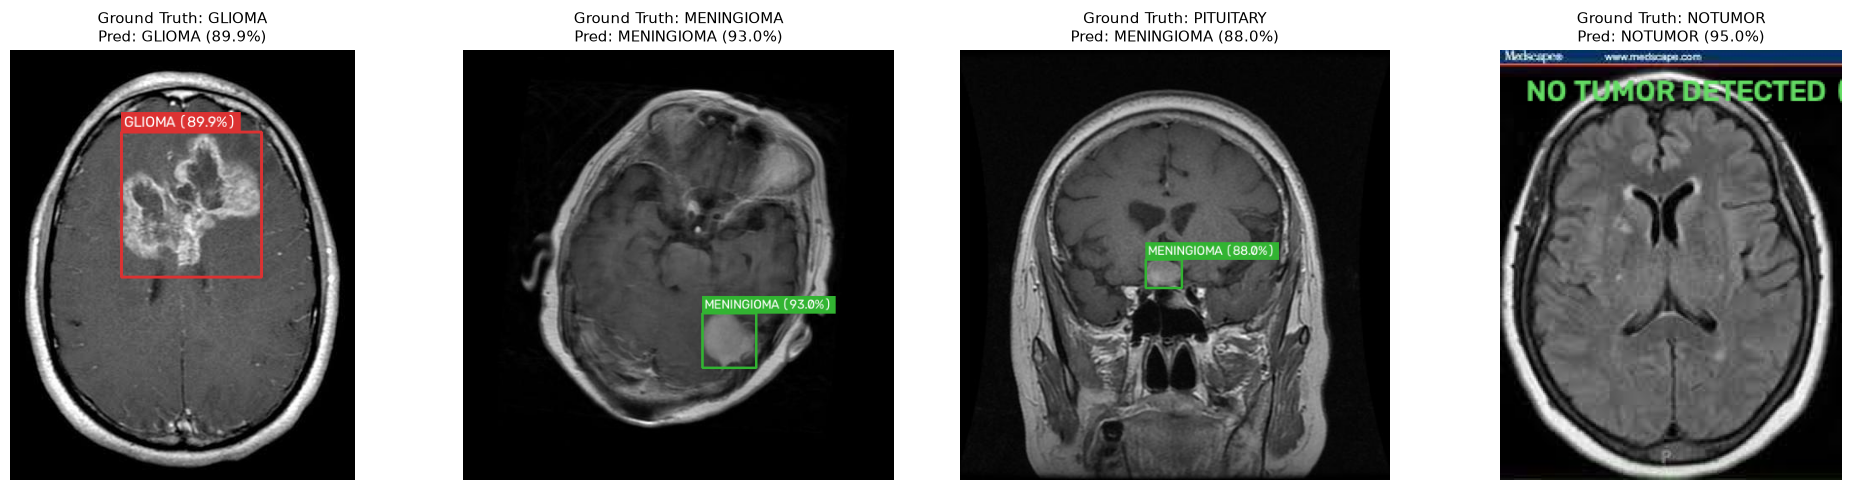

In [4]:
def draw_detection_overlay(result):
    """Draw bounding boxes and labels onto the MRI scan."""
    img = result['orig_img'].copy()
    pred_cls = result['predicted_class']
    conf = result['confidence']
    bbox = result['bbox']
    
    color = CLASS_COLORS.get(pred_cls, (255, 255, 255))
    
    if bbox is not None:
        x1, y1, x2, y2 = bbox
        # Draw box
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        
        # Draw label background and text
        label = f"{pred_cls.upper()} ({conf*100:.1f}%)"
        (w, h), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(img, (x1, y1 - 20), (x1 + w + 6, y1), color, -1)
        cv2.putText(img, label, (x1 + 3, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
    else:
        label = f"NO TUMOR DETECTED ({conf*100:.1f}%)"
        cv2.putText(img, label, (15, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (100, 220, 100), 2)
        
    return img

# Test visualization across all 4 classes
classes_to_test = ['glioma', 'meningioma', 'pituitary', 'notumor']
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for idx, cls in enumerate(classes_to_test):
    # Try images path relative to notebook
    search_path = os.path.join("..", "data", "images", cls, "*.jpg")
    img_files = glob.glob(search_path)
    if not img_files:
        search_path = os.path.join("data", "images", cls, "*.jpg")
        img_files = glob.glob(search_path)
        
    if img_files:
        test_img = img_files[0]
        res = predict_tumor(session, test_img, conf_threshold=0.25)
        annotated = draw_detection_overlay(res)
        
        axes[idx].imshow(annotated)
        axes[idx].set_title(f"Ground Truth: {cls.upper()}\nPred: {res['predicted_class'].upper()} ({res['confidence']*100:.1f}%)", fontsize=11)
        axes[idx].axis('off')
        
plt.tight_layout()
plt.show()


In [5]:
# Systematic Evaluation on Test Subset
test_dir = os.path.join("..", "data", "images")
if not os.path.exists(test_dir):
    test_dir = os.path.join("data", "images")

y_true = []
y_pred = []
results_log = []

for true_class in ['glioma', 'meningioma', 'pituitary', 'notumor']:
    class_folder = os.path.join(test_dir, true_class)
    images = glob.glob(os.path.join(class_folder, "*.jpg"))
    
    for img_path in images:
        pred = predict_tumor(session, img_path, conf_threshold=0.25)
        pred_cls = pred['predicted_class']
        
        y_true.append(true_class)
        y_pred.append(pred_cls)
        
        results_log.append({
            'file': os.path.basename(img_path),
            'true_class': true_class,
            'predicted_class': pred_cls,
            'confidence': pred['confidence'],
            'correct': true_class == pred_cls
        })

# Compute accuracy
correct_count = sum(1 for r in results_log if r['correct'])
total_count = len(results_log)
overall_acc = (correct_count / total_count) * 100 if total_count > 0 else 0

print(f"=== Model Evaluation Results ===")
print(f"Total Evaluated Test Samples: {total_count}")
print(f"Correct Predictions: {correct_count}")
print(f"Overall Accuracy: {overall_acc:.2f}%\n")

# Per-class breakdown
for cls in ['glioma', 'meningioma', 'pituitary', 'notumor']:
    cls_samples = [r for r in results_log if r['true_class'] == cls]
    cls_correct = [r for r in cls_samples if r['correct']]
    acc = (len(cls_correct) / len(cls_samples) * 100) if cls_samples else 0
    print(f"Class '{cls:11}': {len(cls_correct):2d}/{len(cls_samples):2d} ({acc:5.1f}%)")


=== Model Evaluation Results ===
Total Evaluated Test Samples: 40
Correct Predictions: 30
Overall Accuracy: 75.00%

Class 'glioma     ':  8/10 ( 80.0%)
Class 'meningioma ':  8/10 ( 80.0%)
Class 'pituitary  ':  5/10 ( 50.0%)
Class 'notumor    ':  9/10 ( 90.0%)


---
## 2. RAG Prompt Context Fusion (Extended Track Requirement)

Page 3 of the project guidelines requires:
> *"[Extended] Decide how detection/classification output feeds into the RAG prompt context."*

### Context Fusion Mechanism
1. **Extraction**: When an MRI image is uploaded, `extract_vision_rag_context(image_path)` extracts:
   - Primary finding (`pathology_detected`)
   - Model confidence score
   - Localized bounding box coordinates
   - Targeted medical retrieval tags
2. **Context Enrichment**: The detection output produces a standardized clinical finding header that is injected into the LLM system prompt.
3. **Targeted Vector Search**: The vector database query is enriched with the detected pathology name (e.g. `meningioma dural tail surgical resection Simpson grade`), ensuring the retrieved textbook and guideline chunks match the visual evidence.


In [6]:
def extract_vision_rag_context(image_path, user_question=None):
    """
    Converts visual YOLO detections into rich clinical text context
    ready for Vector DB query expansion and LLM prompt fusion.
    """
    pred = predict_tumor(session, image_path, conf_threshold=0.25)
    cls_name = pred['predicted_class']
    conf = pred['confidence']
    bbox = pred['bbox']
    
    if pred['is_tumor']:
        summary = (
            f"[VISUAL DETECTION REPORT]\n"
            f"Image Finding: Intracranial lesion suspicious for {cls_name.upper()} detected.\n"
            f"Model Confidence: {conf * 100:.1f}%\n"
            f"Bounding Box Coordinates: [x1={bbox[0]}, y1={bbox[1]}, x2={bbox[2]}, y2={bbox[3]}]\n"
            f"Clinical Focus: Retrieve WHO CNS classification criteria, imaging hallmarks, and standard-of-care management for {cls_name}."
        )
        expanded_query = f"{user_question or ''} {cls_name} diagnosis management WHO grading guideline".strip()
    else:
        summary = (
            f"[VISUAL DETECTION REPORT]\n"
            f"Image Finding: No focal mass, pathological enhancement, or macroscopic tumor detected.\n"
            f"Model Confidence: {conf * 100:.1f}% (Normal study)\n"
            f"Clinical Focus: Normal brain MRI interpretation, standard anatomical landmarks."
        )
        expanded_query = f"{user_question or ''} normal brain MRI findings negative study differential".strip()
        
    return {
        "finding": cls_name,
        "confidence": conf,
        "bbox": bbox,
        "is_tumor": pred['is_tumor'],
        "visual_prompt_context": summary,
        "expanded_query": expanded_query
    }

# Demonstration with a sample Glioma scan
sample_glioma = glob.glob(os.path.join(test_dir, "glioma", "*.jpg"))[0]
context_payload = extract_vision_rag_context(
    sample_glioma, 
    user_question="What is the recommended standard first-line therapy for this finding?"
)

print("=== FUSED CONTEXT FOR RAG PIPELINE ===")
print(context_payload["visual_prompt_context"])
print("\n=== EXPANDED VECTOR SEARCH QUERY ===")
print(context_payload["expanded_query"])


=== FUSED CONTEXT FOR RAG PIPELINE ===
[VISUAL DETECTION REPORT]
Image Finding: Intracranial lesion suspicious for GLIOMA detected.
Model Confidence: 89.9%
Bounding Box Coordinates: [x1=114, y1=84, x2=258, y2=233]
Clinical Focus: Retrieve WHO CNS classification criteria, imaging hallmarks, and standard-of-care management for glioma.

=== EXPANDED VECTOR SEARCH QUERY ===
What is the recommended standard first-line therapy for this finding? glioma diagnosis management WHO grading guideline
